In [2]:
# Import required libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for cleaner plots
sns.set_theme(style="whitegrid")

# 1. Load the Credit Card Fraud Detection dataset
df = pd.read_csv('card_transdata.csv') # Adjust path if your notebook is inside a 'notebooks/' folder

# 2. Display the first five rows
print("--- First 5 Rows of the Dataset ---")
display(df.head())

# 3. Display the number of rows and columns
print(f"\nDataset Shape: {df.shape[0]} rows and {df.shape[1]} columns")

# 4. Check column names and data types
print("\n--- Data Types & Columns ---")
print(df.dtypes)

# 5. Check target distribution (Legitimate vs Fraudulent)
print("\n--- Target Variable Distribution ---")
print(df['fraud'].value_counts(normalize=True) * 100)

--- First 5 Rows of the Dataset ---


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0



Dataset Shape: 1000000 rows and 8 columns

--- Data Types & Columns ---
distance_from_home                float64
distance_from_last_transaction    float64
ratio_to_median_purchase_price    float64
repeat_retailer                   float64
used_chip                         float64
used_pin_number                   float64
online_order                      float64
fraud                             float64
dtype: object

--- Target Variable Distribution ---
fraud
0.0    91.2597
1.0     8.7403
Name: proportion, dtype: float64


--- Missing Values ---
distance_from_home                0
distance_from_last_transaction    0
ratio_to_median_purchase_price    0
repeat_retailer                   0
used_chip                         0
used_pin_number                   0
online_order                      0
fraud                             0
dtype: int64

--- Duplicate Records ---
Number of duplicate rows: 0

--- Summary Statistics ---


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,26.628792,5.036519,1.824182,0.881536,0.350399,0.100608,0.650552,0.087403
std,65.390784,25.843093,2.799589,0.323157,0.477095,0.300809,0.476796,0.282425
min,0.004874,0.000118,0.004399,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.878008,0.296671,0.475673,1.000000,0.000000,0.000000,0.000000,0.000000
50%,9.967760,0.998650,0.997717,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.743985,3.355748,2.096370,1.000000,1.000000,0.000000,1.000000,0.000000
max,10632.723672,11851.104565,267.802942,1.000000,1.000000,1.000000,1.000000,1.000000



--- Transaction Counts ---
Legitimate Transactions (0): 912,597
Fraudulent Transactions (1): 87,403


C:\Users\shoai\AppData\Local\Temp\ipykernel_14608\3787907958.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='fraud', data=df, palette=['#3498db', '#e74c3c'])
C:\Users\shoai\AppData\Local\Temp\ipykernel_14608\3787907958.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='fraud', y='ratio_to_median_purchase_price', data=df, palette=['#3498db', '#e74c3c'])


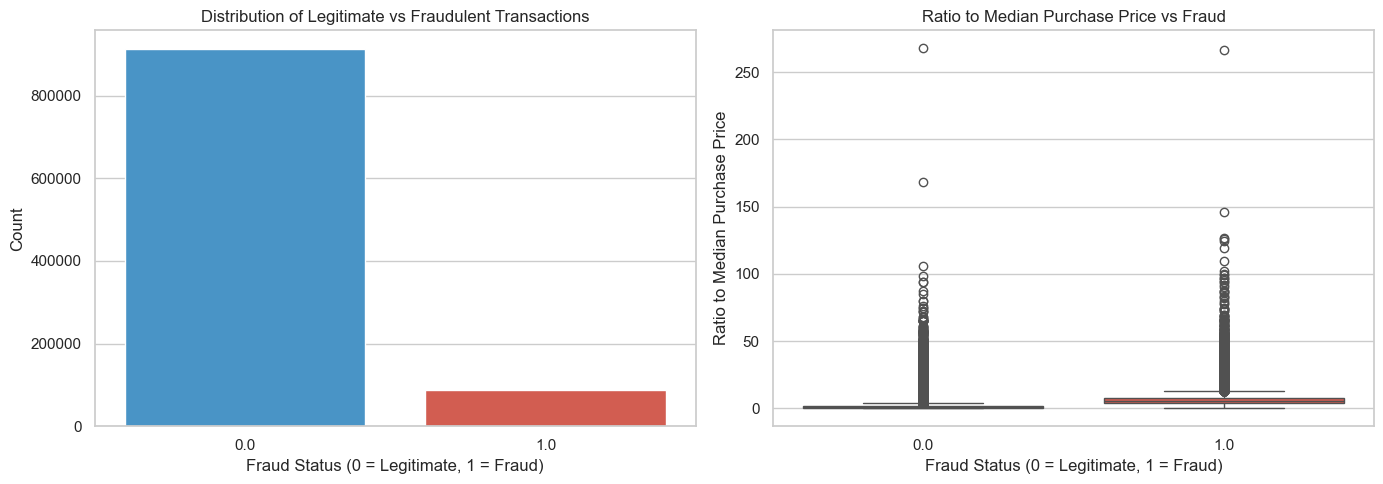

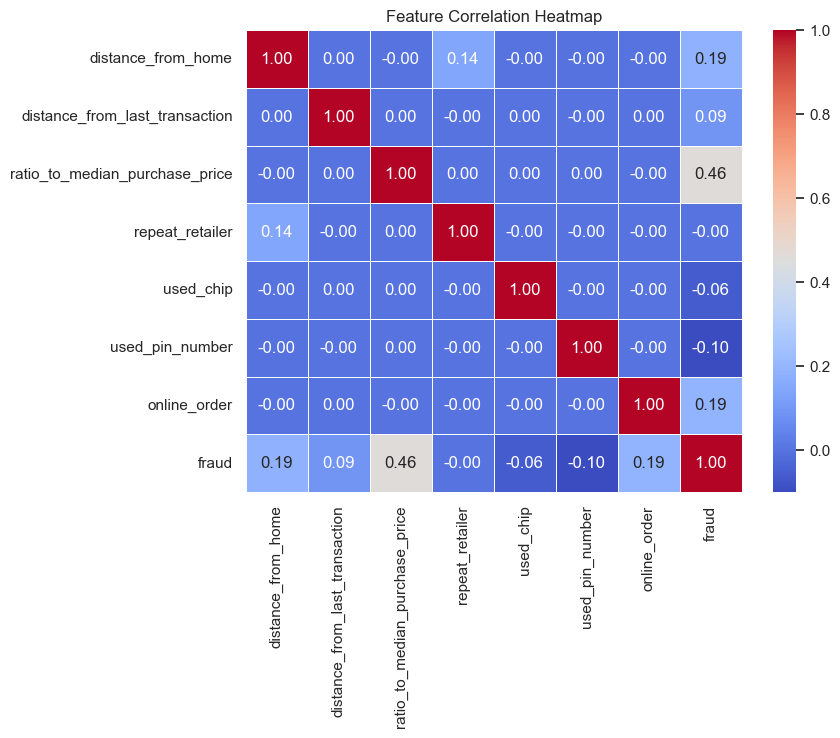

In [3]:
# 1. Check for missing values and duplicates
print("--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Duplicate Records ---")
print(f"Number of duplicate rows: {df.duplicated().sum()}")

# 2. Calculate descriptive statistics
print("\n--- Summary Statistics ---")
display(df.describe())

# 3. Analyze Legitimate vs Fraudulent Transactions count
fraud_counts = df['fraud'].value_counts()
print("\n--- Transaction Counts ---")
print(f"Legitimate Transactions (0): {fraud_counts[0]:,}")
print(f"Fraudulent Transactions (1): {fraud_counts[1]:,}")

# 4. Visualizations
plt.figure(figsize=(14, 5))

# Plot A: Fraud Distribution Count Plot
plt.subplot(1, 2, 1)
sns.countplot(x='fraud', data=df, palette=['#3498db', '#e74c3c'])
plt.title('Distribution of Legitimate vs Fraudulent Transactions')
plt.xlabel('Fraud Status (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Count')

# Plot B: Ratio to Median Purchase Price by Fraud Status (Log scale or capped for better visibility)
plt.subplot(1, 2, 2)
sns.boxplot(x='fraud', y='ratio_to_median_purchase_price', data=df, palette=['#3498db', '#e74c3c'])
plt.title('Ratio to Median Purchase Price vs Fraud')
plt.xlabel('Fraud Status (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Ratio to Median Purchase Price')

plt.tight_layout()
plt.show()

# 5. Correlation Heatmap
plt.figure(figsize=(8, 6))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
import joblib
import os

# 1. Separate Independent Variables (X) and Dependent Variable (y)
X = df.drop(columns=['fraud'])
y = df['fraud']

print(f"Features shape (X): {X.shape}")
print(f"Target shape (y): {y.shape}")

# 2. Train-Test Split (80% training, 20% testing)
# We use stratify=y to ensure the proportion of fraud cases is the same in both train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print(f"\nTraining set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

# 3. Feature Scaling
# Scale numerical columns so features with larger ranges don't dominate the models
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
# IMPORTANT: Use transform (not fit_transform) on test data to prevent data leakage
X_test_scaled = scaler.transform(X_test)

# 4. Handle Imbalanced Data using SMOTE on Training Data ONLY
print("\n--- Class distribution before SMOTE (Training set) ---")
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print("\n--- Class distribution after SMOTE (Training set) ---")
print(pd.Series(y_train_resampled).value_counts())

# 5. Save the scaler and feature names inside a 'model' folder for Flask deployment later
os.makedirs('../model', exist_ok=True)
joblib.dump(scaler, '../model/preprocessor.pkl')
joblib.dump(X.columns.tolist(), '../model/feature_names.pkl')
print("\nScaler and feature names successfully saved in '../model/' folder!")

Features shape (X): (1000000, 7)
Target shape (y): (1000000,)

Training set shape: (800000, 7)
Testing set shape: (200000, 7)

--- Class distribution before SMOTE (Training set) ---
fraud
0.0    730078
1.0     69922
Name: count, dtype: int64

--- Class distribution after SMOTE (Training set) ---
fraud
0.0    730078
1.0    730078
Name: count, dtype: int64

Scaler and feature names successfully saved in '../model/' folder!


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import time

# Initialize models with a random state for reproducibility
models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=50, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss', n_jobs=-1)
}

# Dictionary to store trained models and their predictions
trained_models = {}
model_performance = {}

print("--- Training Models ---")
for name, model in models.items():
    start_time = time.time()
    
    # Train the model using the resampled (SMOTE) training data
    model.fit(X_train_resampled, y_train_resampled)
    
    end_time = time.time()
    
    # Make predictions on the scaled test set
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, "predict_proba") else None
    
    trained_models[name] = model
    print(f"[{name}] Trained in {end_time - start_time:.2f} seconds.")

print("\nAll models trained successfully!")

--- Training Models ---
[Logistic Regression] Trained in 3.79 seconds.
[Decision Tree] Trained in 19.20 seconds.
[Random Forest] Trained in 65.93 seconds.


C:\Users\shoai\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [11:25:05] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[XGBoost] Trained in 9.37 seconds.

All models trained successfully!


--- Model Evaluation Metrics ---

Model: Logistic Regression
  Precision : 0.5774
  Recall    : 0.9481
  F1-Score  : 0.7177
  PR-AUC    : 0.7574

Model: Decision Tree
  Precision : 0.9996
  Recall    : 0.9998
  F1-Score  : 0.9997
  PR-AUC    : 0.9994

Model: Random Forest
  Precision : 0.9999
  Recall    : 0.9997
  F1-Score  : 0.9998
  PR-AUC    : 1.0000

Model: XGBoost
  Precision : 0.9858
  Recall    : 0.9959
  F1-Score  : 0.9908
  PR-AUC    : 0.9998


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Logistic Regression,0.93480,0.577350,0.948115,0.717676,0.979526,0.757372
Decision Tree,0.99995,0.999600,0.999828,0.999714,0.999895,0.999443
Random Forest,0.99997,0.999943,0.999714,0.999828,1.000000,1.000000
XGBoost,0.99839,0.985788,0.995938,0.990837,0.999985,0.999845



🏆 Best Model Selected: Random Forest (based on highest PR-AUC)

--- Classification Report for Random Forest ---
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00    182519
         1.0       1.00      1.00      1.00     17481

    accuracy                           1.00    200000
   macro avg       1.00      1.00      1.00    200000
weighted avg       1.00      1.00      1.00    200000



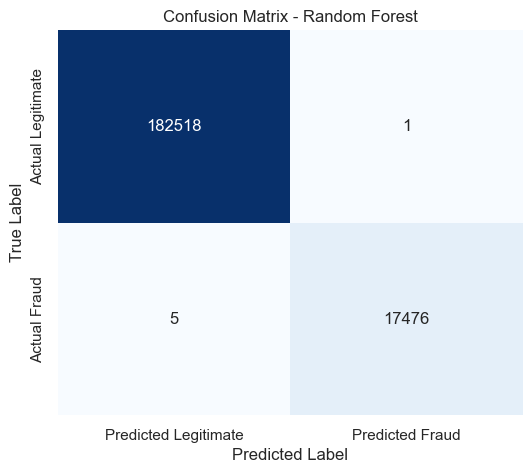


Best model successfully saved to ../model/fraud_model.pkl!


In [6]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    roc_auc_score, average_precision_score, confusion_matrix, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pandas as pd

# 1. Evaluate all models and store metrics
evaluation_results = {}

print("--- Model Evaluation Metrics ---")
for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, "predict_proba") else None
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob) if y_prob is not None else 0
    pr_auc = average_precision_score(y_test, y_prob) if y_prob is not None else 0
    
    evaluation_results[name] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    }
    
    print(f"\nModel: {name}")
    print(f"  Precision : {prec:.4f}")
    print(f"  Recall    : {rec:.4f}")
    print(f"  F1-Score  : {f1:.4f}")
    print(f"  PR-AUC    : {pr_auc:.4f}")

# Convert results to DataFrame for easy comparison
metrics_df = pd.DataFrame(evaluation_results).T
display(metrics_df)

# 2. Select Best Model based on F1-Score & PR-AUC (critical for fraud detection)
best_model_name = metrics_df['PR-AUC'].idxmax()
best_model = trained_models[best_model_name]

print(f"\n🏆 Best Model Selected: {best_model_name} (based on highest PR-AUC)")

# 3. Detailed classification report and confusion matrix for the best model
y_pred_best = best_model.predict(X_test_scaled)
print(f"\n--- Classification Report for {best_model_name} ---")
print(classification_report(y_test, y_pred_best))

plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Legitimate', 'Predicted Fraud'],
            yticklabels=['Actual Legitimate', 'Actual Fraud'])
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# 4. Save the best model to the '../model/' folder
model_path = '../model/fraud_model.pkl'
joblib.dump(best_model, model_path)
print(f"\nBest model successfully saved to {model_path}!")